In [ ]:

from google.colab import files

uploaded = files.upload()


Saving amazon_ecommerce_eda_sample.csv to amazon_ecommerce_eda_sample.csv


In [ ]:

import pandas as pd

df = pd.read_csv("amazon_ecommerce_eda_sample.csv")

df.head()


,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,ASIN,Courier Status,Qty,Amount,B2B,Currency,Color,Unit Price,Order Month,Return Flag
0,854-2719583-2458591,06-20-22,Shipped,Merchant,Amazon.in,Expedited,SET2169,J0208-DR-3XL,Set,3XL,B0W671412,Cancelled,1,831.57,False,INR,Red,831.57,2022-06,False
1,259-4612365-6647119,03-31-22,Shipped,Amazon,Amazon.in,Expedited,J02572,SET3405-KR-3XL,Saree,XL,B0R230889,Cancelled,2,3609.44,True,INR,Red,1804.72,2022-03,False
2,171-1768805-4823498,06-19-22,Shipped,Merchant,Non-Amazon,Standard,JNE1656,SET1957-TP-M,Ethnic Dress,L,B0L319684,In Transit,2,2061.52,False,INR,Black,1030.76,2022-06,False
3,488-5528972-4684531,06-16-22,Shipped,Merchant,Amazon.in,Standard,SET3466,JNE3397-TP-XL,Blouse,L,B0C321231,In Transit,1,1875.99,False,INR,Maroon,1875.99,2022-06,False
4,674-5408072-8187926,05-20-22,Shipped,Merchant,Amazon.in,Standard,SET2187,SET472-KR-S,Blouse,M,B0U267753,Cancelled,1,808.22,False,INR,Yellow,808.22,2022-05,False


In [ ]:

import pandas as pd

df = pd.read_csv("amazon_ecommerce_eda_sample.csv")

df.head()


,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,ASIN,Courier Status,Qty,Amount,B2B,Currency,Color,Unit Price,Order Month,Return Flag
0,854-2719583-2458591,06-20-22,Shipped,Merchant,Amazon.in,Expedited,SET2169,J0208-DR-3XL,Set,3XL,B0W671412,Cancelled,1,831.57,False,INR,Red,831.57,2022-06,False
1,259-4612365-6647119,03-31-22,Shipped,Amazon,Amazon.in,Expedited,J02572,SET3405-KR-3XL,Saree,XL,B0R230889,Cancelled,2,3609.44,True,INR,Red,1804.72,2022-03,False
2,171-1768805-4823498,06-19-22,Shipped,Merchant,Non-Amazon,Standard,JNE1656,SET1957-TP-M,Ethnic Dress,L,B0L319684,In Transit,2,2061.52,False,INR,Black,1030.76,2022-06,False
3,488-5528972-4684531,06-16-22,Shipped,Merchant,Amazon.in,Standard,SET3466,JNE3397-TP-XL,Blouse,L,B0C321231,In Transit,1,1875.99,False,INR,Maroon,1875.99,2022-06,False
4,674-5408072-8187926,05-20-22,Shipped,Merchant,Amazon.in,Standard,SET2187,SET472-KR-S,Blouse,M,B0U267753,Cancelled,1,808.22,False,INR,Yellow,808.22,2022-05,False


In [ ]:

df.shape


(800, 20)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Order ID            800 non-null    object 
 1   Date                800 non-null    object 
 2   Status              800 non-null    object 
 3   Fulfilment          800 non-null    object 
 4   Sales Channel       800 non-null    object 
 5   ship-service-level  800 non-null    object 
 6   Style               800 non-null    object 
 7   SKU                 800 non-null    object 
 8   Category            800 non-null    object 
 9   Size                800 non-null    object 
 10  ASIN                800 non-null    object 
 11  Courier Status      800 non-null    object 
 12  Qty                 800 non-null    int64  
 13  Amount              800 non-null    float64
 14  B2B                 800 non-null    bool   
 15  Currency            800 non-null    object 
 16  Color   

In [ ]:
df.isnull().sum()

,0
Order ID,0
Date,0
Status,0
Fulfilment,0
Sales Channel,0
ship-service-level,0
Style,0
SKU,0
Category,0
Size,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Order ID"].duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Qty,Amount,Unit Price
count,800.000000,800.000000,800.000000
mean,1.527500,2044.975925,1334.311350
std,0.809359,1552.555742,658.208395
min,1.000000,202.980000,202.140000
25%,1.000000,954.770000,766.770000
50%,1.000000,1720.975000,1319.415000
75%,2.000000,2441.077500,1883.805000
max,4.000000,9695.120000,2497.350000


In [ ]:
df.groupby("Category")["Amount"].sum().sort_values(ascending=False)

,Amount
Category,
Blouse,267844.26
Saree,260550.37
Western Dress,248004.74
kurta,245593.79
Top,219391.18
Ethnic Dress,199004.10
Set,195592.30


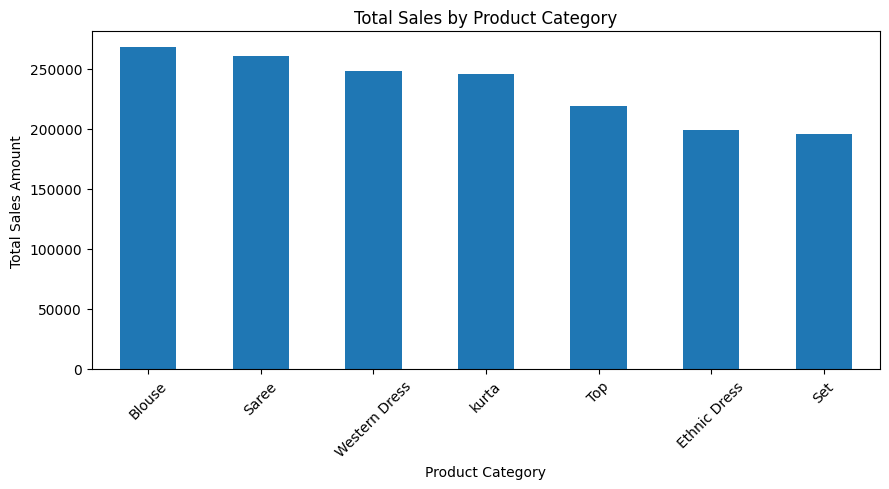

In [ ]:
import matplotlib.pyplot as plt

sales = df.groupby("Category")["Amount"].sum().sort_values(ascending=False)

sales.plot(kind="bar", figsize=(9, 5))

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.month

monthly_sales = df.groupby("Month")["Amount"].sum()

monthly_sales

/tmp/ipykernel_1040/3845366203.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"])


,Amount
Month,
3,22720.55
4,550977.53
5,598463.17
6,463819.49


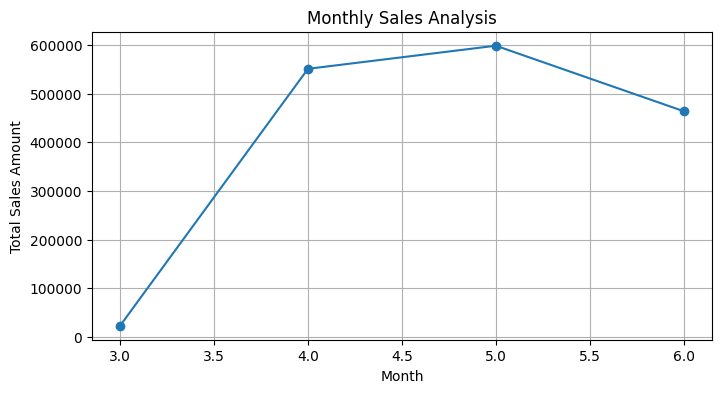

In [ ]:
monthly_sales.plot(kind="line", marker="o", figsize=(8, 4))

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.grid(True)
plt.show()

In [ ]:
df["Status"].value_counts()

,count
Status,
Shipped,417
Shipped - Delivered to Buyer,195
Cancelled,102
Shipped - Returned to Seller,50
Pending,36


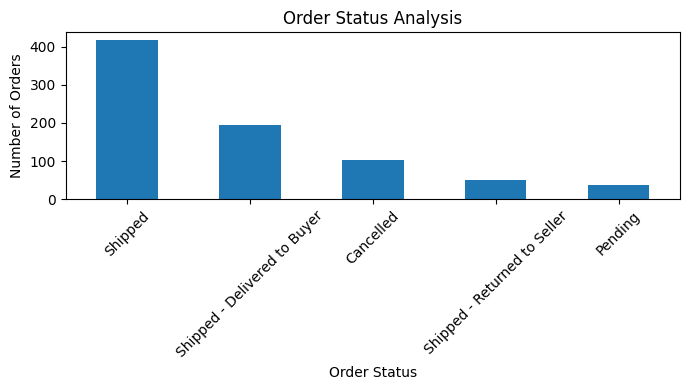

In [ ]:
import matplotlib.pyplot as plt
df["Status"].value_counts().plot(
    kind="bar",
    figsize=(7, 4)
    )
plt.title("Order Status Analysis")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
channel_sales = df.groupby("Sales Channel")["Amount"].sum()

channel_sales.sort_values(ascending=False)

,Amount
Sales Channel,
Amazon.in,1524595.61
Non-Amazon,111385.13


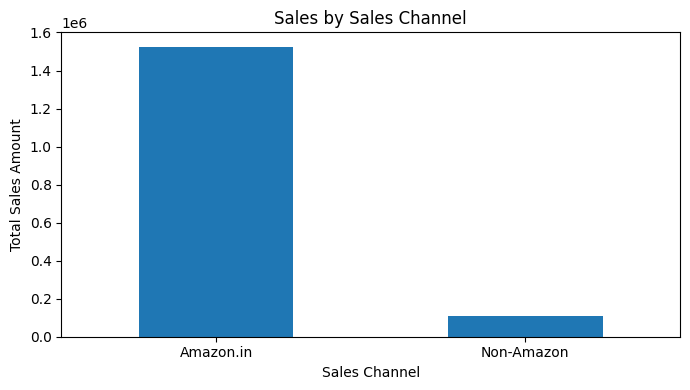

In [ ]:
import matplotlib.pyplot as plt
channel_sales.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(7, 4)
  )
plt.title("Sales by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print("Total Sales:", df["Amount"].sum())
print("Average Order Amount:", df["Amount"].mean())
print("Highest Order Amount:", df["Amount"].max())
print("Lowest Order Amount:", df["Amount"].min())


Total Sales: 1635980.74
Average Order Amount: 2044.975925
Highest Order Amount: 9695.12
Lowest Order Amount: 202.98


In [ ]:
top_products = (
    df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
 )
top_products

,Amount
Category,
Blouse,267844.26
Saree,260550.37
Western Dress,248004.74
kurta,245593.79
Top,219391.18


In [ ]:
print("Total Orders:", len(df))
print("Total Categories:", df["Category"].nunique())
print("Most Sold Category:",
      df.groupby("Category")["Qty"].sum().idxmax())
print("Highest Sales Category:",
      df.groupby("Category")["Amount"].sum().idxmax())
print("Most Common Order Status:",
      df["Status"].mode()[0])

Total Orders: 800
Total Categories: 7
Most Sold Category: Saree
Highest Sales Category: Blouse
Most Common Order Status: Shipped
